# 04 · diffhydro: the same physics, production-grade

In Part I, we built every piece by hand: finite volumes, Riemann solvers, MUSCL, SSP-RK, gradients through time.
From here on we use **diffhydro**, a JAX hydrodynamics code that provides those pieces as interchangeable components,
in 1D/2D/3D, sharded across GPUs, with extra physics (self-gravity, cooling, conduction, MHD, cosmology), and
**differentiable end to end**.

**In this notebook you will:**
- map every concept from notebook 03 onto the diffhydro API,
- reproduce the Sod shock tube and compare against the exact solution *and* our hand-written solver,
- swap Riemann solvers and reconstructions with one line each,
- run a **2D Kelvin–Helmholtz** instability,
- differentiate through `diffhydro` to infer an initial state, exactly as in notebook 03.

In [ ]:
import sys, time
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

try:
    import diffhydro as dh
except ImportError:                      # running from a source checkout without `pip install -e .`
    sys.path.insert(0, "../..")
    import diffhydro as dh
import tutorial_utils as tu

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "image.interpolation": "nearest"})
print("JAX backend:", jax.default_backend()) #If you are on mac, check out mac metal for more acceleration!

JAX backend: cpu


## 1. From our solver to diffhydro

| notebook 03 | diffhydro | notes |
|---|---|---|
| $\gamma$, `prim_to_cons`, `cons_to_prim` | `eq = dh.equationmanager.EquationManager()`; `eq.gamma`, `eq.cfl` | `eq.get_conservatives_from_primitives(W)` / `eq.get_primitives_from_conservatives(U)` |
| `rusanov`, `hll`, `hllc` | `dh.LaxFriedrichs`, `dh.HLL`, `dh.HLLC` | take a signal-speed estimate, e.g. `dh.signal_speed_Rusanov` |
| no slope / `minmod` / `mc` | `dh.WENO1()`, `dh.MUSCL3(limiter="MINMOD")`, `dh.MUSCL3(limiter="MC")` | limiters: `MINMOD, MC, VANLEER, VANALBADA, SUPERBEE, KOREN` |
| `rhs` (face fluxes → divergence) | `dh.ConvectiveFlux(eq, riemann_solver, reconstruction)` | `positivity=True` falls back to 1st order where a face state would be unphysical |
| `ssprk2` + time loop | `dh.hydro(fluxes=[...], use_mol=True, integrator="RK2" / "SSPRK3" / "RK4")` | unsplit method-of-lines |

A few conventions to know:

* **The state is always `(n_vars, nx, ny, nz)`** in *conservative* variables $(\rho, \rho v_x, \rho v_y, \rho v_z, E)$,
  with three velocity components even in 1D. A 1D run is `(5, N, 1, 1)`, a 2D run `(5, nx, ny, 1)`.
* **Boundaries are periodic** (`jnp.roll`) in the default single-device setup. There's no outflow boundary here, so we put
  the shock tube on a **doubled, mirror-symmetric periodic domain**: two Sod problems back to back.
* The grid spacing is `ConvectiveFlux.dx_o` (default 1, i.e. *cell units*); we set it to the physical $\Delta x$.
* `ignore_singleton_axes=True` stops size-1 axes from shrinking the CFL time step in 1D/2D runs. For the most part diffhydro's API is optimized for 3d runs, but maintains lower dimensional compatability for testing and demonstration.

DiffHydro's evolution is set-up in a functional way. While individual physics/solver modules are classes, it creates (potential) issues to change class proprties over the course of the simulation for inference problems. It is set up for the state of the simulation to be held in the `state` and `params` objects and for each operation to take these objects as input/output. 

In [ ]:
def make_sim(nx, ny=1, box=1.0, gamma=1.4, riemann=dh.HLLC, recon=None, integrator="SSPRK3", cfl=0.4, max_steps=20000):
    eq = dh.equationmanager.EquationManager() #holds geometry and basic physics constants
    eq.mesh_shape = [nx, ny, 1] 
    eq.gamma, eq.cfl = gamma, cfl
    flux = dh.ConvectiveFlux(eq,
                             riemann(equation_manager=eq, signal_speed=dh.signal_speed_Rusanov),
                             recon if recon is not None else dh.MUSCL3(limiter="MC"),
                             ignore_singleton_axes=True)
    flux.dx_o = box / nx
    sim = dh.hydro(n_super_step=max_steps, fluxes=[flux], forces=[], max_dt=1.0,
                   use_mol=True, integrator=integrator)
    return eq, sim

# doubled Sod tube on a periodic box of length 2: high pressure in the middle
N, box = 400, 2.0
x = (np.arange(N) + 0.5) * box / N
inside = (x > 0.5) & (x < 1.5)

def sod_state(eq, pL=1.0, rhoL=1.0):
    W = jnp.stack([jnp.where(inside, rhoL, 0.125), 0 * x, 0 * x, 0 * x, jnp.where(inside, pL, 0.1)])
    return eq.get_conservatives_from_primitives(W[:, :, None, None])     # -> (5, N, 1, 1)

eq, sim = make_sim(N, box=box)
U, params, t, dt_hist, nsteps = sim.evolve_till_time(sod_state(eq), {}, 0.2)
W = eq.get_primitives_from_conservatives(U)[:, :, 0, 0]
print(f"reached t = {float(t):.4f} in {int(nsteps)} steps;  state shape {U.shape};  params = {params}")

reached t = 0.2004 in 219 steps;  state shape (5, 400, 1, 1);  params = {'_hydro_repair_count': Array(0, dtype=int32)}


`evolve_till_time` returns the final conservative state, the `params` dict (diffhydro uses it to carry auxiliary
state; here it only counts repaired cells), the time actually reached, the history of time steps and the
number of steps. The last step is not clipped, so $t$ slightly overshoots 0.2 and we evaluate the exact solution at
the reached time. The right half of the box, $x \in [1, 2]$, is a standard Sod tube with its diaphragm at $x = 1.5$.

L1(rho):  diffhydro 0.0029   hand-written 0.0026


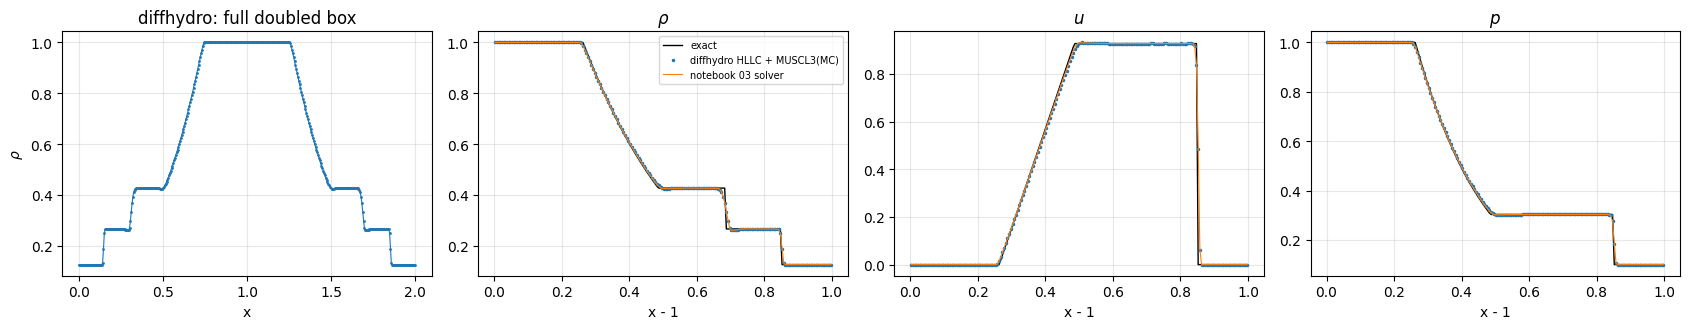

In [3]:
t_reached = float(t)
xr = x[N // 2:] - 1.0                                  # right half, shifted so the diaphragm sits at 0.5
rho_ex, u_ex, p_ex = tu.exact_riemann(1.0, 0.0, 1.0, 0.125, 0.0, 0.1, xr, t_reached)

# our notebook-03 solver on the same resolution (dx = 0.005), outflow boundaries on [0, 1]
W_hand = np.asarray(tu.solve(np.stack([np.where(xr < 0.5, 1.0, 0.125), 0 * xr, np.where(xr < 0.5, 1.0, 0.1)]),
                             box / N, t_reached, riemann=tu.hllc, limiter=tu.mc))

fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
axes[0].plot(x, W[0], ".-", ms=2, lw=0.8); axes[0].set_title("diffhydro: full doubled box"); axes[0].set_ylabel(r"$\rho$")
for ax, i, ex, lab in zip(axes[1:], (0, 1, 4), (rho_ex, u_ex, p_ex), (r"$\rho$", "$u$", "$p$")):
    ax.plot(xr, ex, "k", lw=1, label="exact")
    ax.plot(xr, W[i][N // 2:], ".", ms=3, label="diffhydro HLLC + MUSCL3(MC)")
    ax.plot(xr, W_hand[{0: 0, 1: 1, 4: 2}[i]], "-", lw=0.8, label="notebook 03 solver")
    ax.set_title(lab); ax.set_xlabel("x - 1")
axes[1].legend(fontsize=7); axes[0].set_xlabel("x")
plt.tight_layout()
print(f"L1(rho):  diffhydro {np.mean(np.abs(np.asarray(W[0][N // 2:]) - rho_ex)):.4f}   "
      f"hand-written {np.mean(np.abs(W_hand[0] - rho_ex)):.4f}")

Same answer as our hand-written solver, to within the small differences in reconstruction details (diffhydro's
`MUSCL3` and its RK3 integrator vs our RK2), and both match the exact solution. Note the perfect mirror symmetry of
the doubled box. Breaking it would indicate a bug: always a good free test.

### Swapping components

Every component is a constructor argument, so comparing schemes is a loop:

L1 density error x 1e3 on the Sod tube (N = 200 per tube)

                   WENO1 (1st order)       MUSCL3 minmod           MUSCL3 MC
LaxFriedrichs                  21.33                5.97                3.73
HLL                            18.30                5.28                3.48
HLLC                           14.79                4.51                2.91


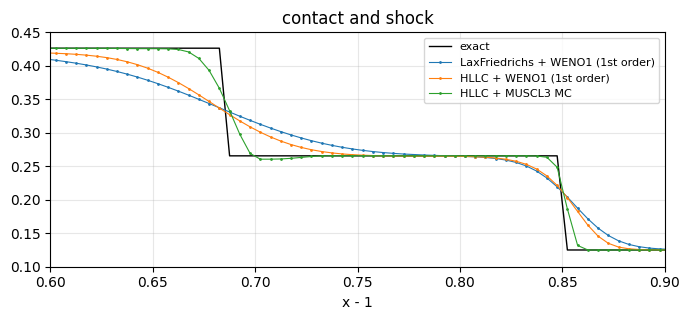

In [4]:
riemanns = {"LaxFriedrichs": dh.LaxFriedrichs, "HLL": dh.HLL, "HLLC": dh.HLLC}
recons = {"WENO1 (1st order)": lambda: dh.WENO1(), "MUSCL3 minmod": lambda: dh.MUSCL3(limiter="MINMOD"),
          "MUSCL3 MC": lambda: dh.MUSCL3(limiter="MC")}
table = np.zeros((len(riemanns), len(recons)))
profiles = {}
for i, (rn, R) in enumerate(riemanns.items()):
    for j, (cn, C) in enumerate(recons.items()):
        eq_, sim_ = make_sim(N, box=box, riemann=R, recon=C())
        U_, _, t_, _, _ = sim_.evolve_till_time(sod_state(eq_), {}, 0.2)
        rho_ = np.asarray(eq_.get_primitives_from_conservatives(U_)[0, N // 2:, 0, 0])
        exact_ = tu.exact_riemann(1.0, 0.0, 1.0, 0.125, 0.0, 0.1, xr, float(t_))[0]
        table[i, j] = np.mean(np.abs(rho_ - exact_))
        profiles[(rn, cn)] = rho_

print("L1 density error x 1e3 on the Sod tube (N = 200 per tube)\n")
print(f"{'':16s}" + "".join(f"{c:>20s}" for c in recons))
for i, rn in enumerate(riemanns):
    print(f"{rn:16s}" + "".join(f"{1e3 * v:20.2f}" for v in table[i]))

fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(xr, rho_ex, "k", lw=1, label="exact")
for key in [("LaxFriedrichs", "WENO1 (1st order)"), ("HLLC", "WENO1 (1st order)"), ("HLLC", "MUSCL3 MC")]:
    ax.plot(xr, profiles[key], ".-", ms=2, lw=0.8, label=" + ".join(key))
ax.set_xlim(0.6, 0.9); ax.set_ylim(0.1, 0.45); ax.legend(fontsize=8); ax.set_xlabel("x - 1"); ax.set_title("contact and shock")
plt.tight_layout()

The same ranking as notebook 03: HLLC beats HLL beats Lax–Friedrichs, and reconstruction matters more than the
Riemann solver. diffhydro offers more (e.g. `dh.PPM`, `dh.TENO5_alt`, Davis/Einfeldt/Toro signal speeds, an MHD
`HLLD_MHD`), but HLLC + MUSCL3 is a robust default and is what we use for the rest of the series.

## 2. The evolve family

`dh.hydro` offers several drivers; choosing the right one matters once gradients are involved (in the future this might be more automatic):

| method | time stepping | returns | differentiable? | use for |
|---|---|---|---|---|
| `evolve_till_time(U, params, t)` | adaptive CFL, `while_loop` until $t$ | `U, params, t, dt_hist, n` | unstable (`while_loop`) | forward runs to a given time |
| `evolve(U, params)` | adaptive CFL, `n_super_step` steps | `U, params` | yes | fixed number of steps |
| `evolve_memory_efficient(U, params, checkpoint_every=10)` | adaptive, `n_super_step` steps | `U, params` | yes, $\mathcal O(N/k)$ memory | long differentiable runs |
| `evolve_with_dt_schedule(U, params, dts)` | **you give the $\Delta t$ array** | `U, params, t` | yes, per-step checkpointing | inverse problems with a fixed end time |

With adaptive steps, both the time step and the *final time* depend on the initial condition, and gradients flow
through them. That is legitimate but it makes losses harder to interpret since it mixes the time evolution with the total time for the sim. For inverse problems I usually prefer
**`evolve_with_dt_schedule`** with a fixed, safely small $\Delta t$, exactly like `forward()` in notebook 03.

Two practical notes:
* On GPU the input state buffer is **donated** (reused for the output) for extra memory efficiency. Don't reuse `U0` after passing it to an
  `evolve*` call; rebuild it from a function, as we do with `sod_state(eq)` or use the `copy` library before hand to save the state as a seperate variable.
* `n_super_step` is the step budget for `evolve_till_time` and the exact step count for `evolve`/`evolve_memory_efficient`.

## 3. Going 2D: the Kelvin–Helmholtz instability

Changing to 2D only changes `mesh_shape` and the shape of the initial state. A dense stripe moving right inside a
lighter medium moving left is unstable to shear: small ripples on the interfaces roll up into the familiar
Kelvin–Helmholtz billows.

128x128 KH to t = 3 in 39.3 s


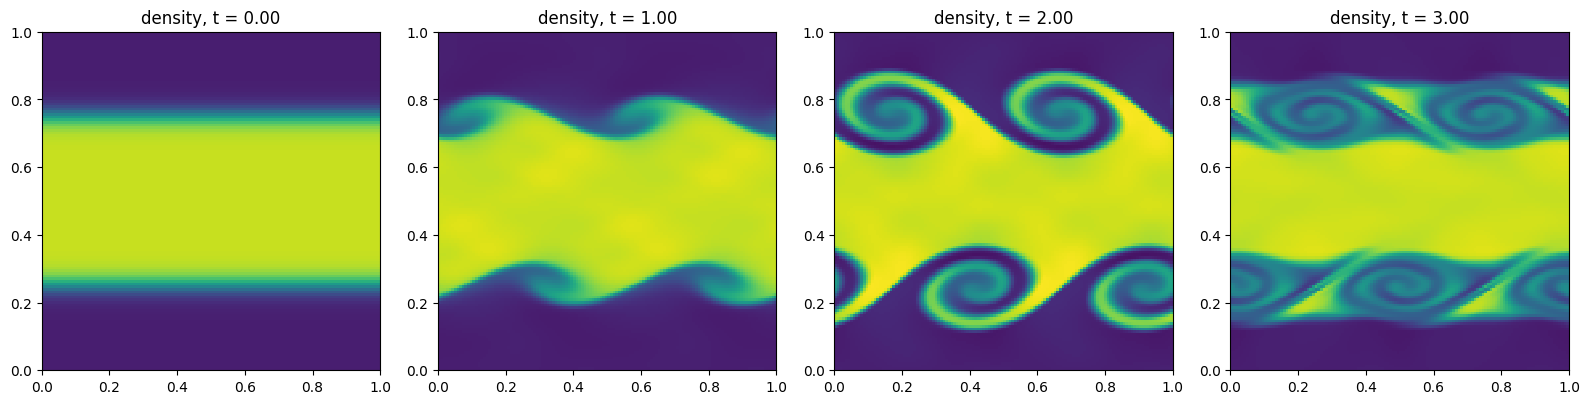

In [5]:
n = 128
eq2, sim2 = make_sim(n, n, box=1.0, gamma=5 / 3, integrator="RK2")

def kh_state(eq, n, amp=0.1, width=0.035):
    c = (jnp.arange(n) + 0.5) / n
    X, Y = jnp.meshgrid(c, c, indexing="ij")
    stripe = 0.5 * (jnp.tanh((Y - 0.25) / width) - jnp.tanh((Y - 0.75) / width))    # 0 outside, 1 inside
    seed = amp * jnp.sin(4 * jnp.pi * X) * (jnp.exp(-((Y - 0.25) / width) ** 2) + jnp.exp(-((Y - 0.75) / width) ** 2))
    W = jnp.stack([1.0 + stripe, stripe - 0.5, seed, 0 * X, 2.5 + 0 * X])     # rho, vx, vy, vz, p
    return eq.get_conservatives_from_primitives(W[..., None])              # -> (5, n, n, 1)

U2 = kh_state(eq2, n)
snaps, times = [np.asarray(U2[0, :, :, 0])], [0.0]
t0 = time.perf_counter()
for t_target in (1.0, 2.0, 3.0):
    U2, _, t_now, _, _ = sim2.evolve_till_time(U2, {}, t_target - times[-1])   # continue from the current state
    snaps.append(np.asarray(U2[0, :, :, 0])); times.append(times[-1] + float(t_now))
print(f"{n}x{n} KH to t = 3 in {time.perf_counter() - t0:.1f} s")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, s, tt in zip(axes, snaps, times):
    ax.imshow(s.T, origin="lower", cmap="viridis", extent=[0, 1, 0, 1], vmin=0.9, vmax=2.1)
    ax.set_title(f"density, t = {tt:.2f}"); ax.grid(False)
plt.tight_layout()

(`evolve_till_time` measures time from the start of each call, so we just continue from the returned state.)

## 4. Gradients through diffhydro

The payoff of building on JAX: the same `jax.grad` machinery from Part I works on diffhydro. Let's redo the shock-tube
inference with diffhydro as the forward model. We recover the left pressure **and** density from a noisy density
profile. (In diffhydro, $\gamma$ is a static Python float on the `EquationManager`, not a traced input, so we infer
$\rho_L$ instead.)

The forward model uses `evolve_with_dt_schedule` with a fixed $\Delta t$. Note diffhydro runs in **float32**: expect
gradient checks to agree to ~$10^{-3}$, not $10^{-10}$ (notebook 02).

In [6]:
N, box = 200, 2.0                      # coarser than above to keep the CPU run short
x = (np.arange(N) + 0.5) * box / N
inside = (x > 0.5) & (x < 1.5)
eq3, sim3 = make_sim(N, box=box)
T, n_steps = 0.2, 150
dts = jnp.full((n_steps,), T / n_steps)    # CFL ~ 0.3 for the whole prior range

def forward(theta):
    U0 = sod_state(eq3, pL=jnp.exp(theta[0]), rhoL=jnp.exp(theta[1]))
    U, _, _ = sim3.evolve_with_dt_schedule(U0, {}, dts)
    return eq3.get_primitives_from_conservatives(U)[0, :, 0, 0]

theta_true = jnp.zeros(2)                                   # p_L = rho_L = 1
sigma_n = 0.01
data = forward(theta_true) + sigma_n * jnp.asarray(np.random.default_rng(0).standard_normal(N), jnp.float32)
loss = jax.jit(lambda th: jnp.mean((forward(th) - data) ** 2) / sigma_n ** 2)
vg = jax.jit(jax.value_and_grad(loss))

theta0 = jnp.array([np.log(0.4), np.log(2.0)], jnp.float32)
l0, g0 = vg(theta0)
eps = 1e-2
fd = [(loss(theta0.at[i].add(eps)) - loss(theta0.at[i].add(-eps))) / (2 * eps) for i in range(2)]
print("autodiff grad:", np.asarray(g0), "   finite diff:", np.asarray(fd))

autodiff grad: [ -961.1765 20668.008 ]    finite diff: [ -961.6211 20670.338 ]


120 Adam steps in 102.8 s ->  p_L = 0.9944,  rho_L = 1.0014  (true 1, 1)


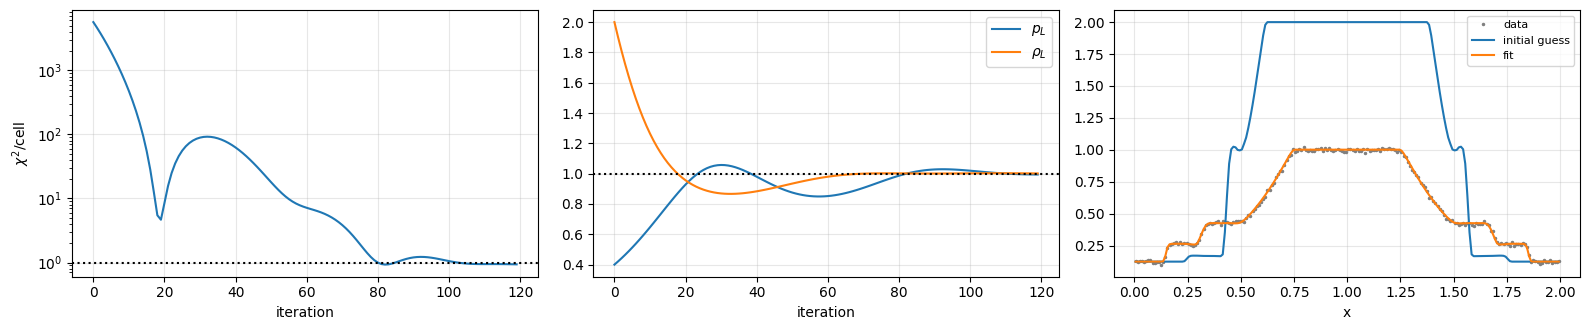

In [7]:
theta, st, path, hist = theta0, tu.adam_init(theta0), [], []
t0 = time.perf_counter()
for i in range(120):
    l, g = vg(theta)
    path.append(np.exp(np.asarray(theta))); hist.append(float(l))
    theta, st = tu.adam_step(theta, g, st, lr=0.05)
print(f"120 Adam steps in {time.perf_counter() - t0:.1f} s ->  p_L = {np.exp(theta[0]):.4f},  rho_L = {np.exp(theta[1]):.4f}  (true 1, 1)")

path = np.array(path)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
axes[0].semilogy(hist); axes[0].axhline(1, color="k", ls=":"); axes[0].set_xlabel("iteration"); axes[0].set_ylabel(r"$\chi^2$/cell")
axes[1].plot(path[:, 0], label="$p_L$"); axes[1].plot(path[:, 1], label=r"$\rho_L$"); axes[1].axhline(1, color="k", ls=":")
axes[1].legend(); axes[1].set_xlabel("iteration")
axes[2].plot(x, data, ".", ms=3, color="gray", label="data"); axes[2].plot(x, forward(theta0), label="initial guess")
axes[2].plot(x, forward(theta), label="fit"); axes[2].legend(fontsize=8); axes[2].set_xlabel("x")
plt.tight_layout()

Everything from Part I carries over. The gradient agrees with finite differences to float32 precision, and Adam
finds the truth.

**A note on speed.** On a CPU the backward pass through diffhydro's HLLC solver is much slower relative to the
forward pass (~10–20×) than on a GPU (~3×), because XLA's CPU backend executes the many small elementwise kernels of the
adjoint one by one. The 1D problems here are fine on a laptop. For 2D inverse problems at interesting resolutions
(notebook 06) a GPU makes the difference between minutes and hours.

## Summary and what's next

* diffhydro = the notebook 03 recipe as configurable components: `EquationManager` + `ConvectiveFlux(Riemann, Recon)` + `hydro(integrator)`.
* States are `(5, nx, ny, nz)` conservatives; boundaries are periodic, and 1D/2D just use size-1 axes.
* `evolve_till_time` for forward runs; **`evolve_with_dt_schedule`** for differentiable runs with a fixed end time.
* `jax.grad` works through the whole thing.

In **notebook 05** we use diffhydro to study **decaying turbulence** in 2D: Gaussian random fields, power spectra,
energy cascades, the lognormal density PDF. We also build the differentiable turbulent initial-condition generator
that notebook 06 will optimise.